In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cybersecurity_incidents.csv")

print(df.head())
print(df.columns)

  incident_id        date organization     attack_type  severity  \
0     INC1000  2023-04-13    CyberGrid      Ransomware    Medium   
1     INC1001  2024-03-11   DataSecure        Phishing  Critical   
2     INC1002  2023-09-28     BitGuard      Ransomware    Medium   
3     INC1003  2023-04-17    CyberGrid  Insider Threat    Medium   
4     INC1004  2023-03-13     BitGuard         Malware      High   

   data_loss_gb  financial_impact_usd  region  detected_by  \
0          3.36              55657.21  Africa  SOC Analyst   
1         21.22              71185.04  Europe  User Report   
2          1.39              54370.83  Europe  SOC Analyst   
3          5.58              19578.63    Asia          IDS   
4          7.17              76233.68  Europe  SOC Analyst   

   response_time_hours  resolved  
0                 23.1     False  
1                 70.5      True  
2                 13.4      True  
3                  2.2      True  
4                 55.2      True  
Index(['

1️⃣ Bar Chart  
→ Plot a bar chart showing the number of incidents per attack_type.

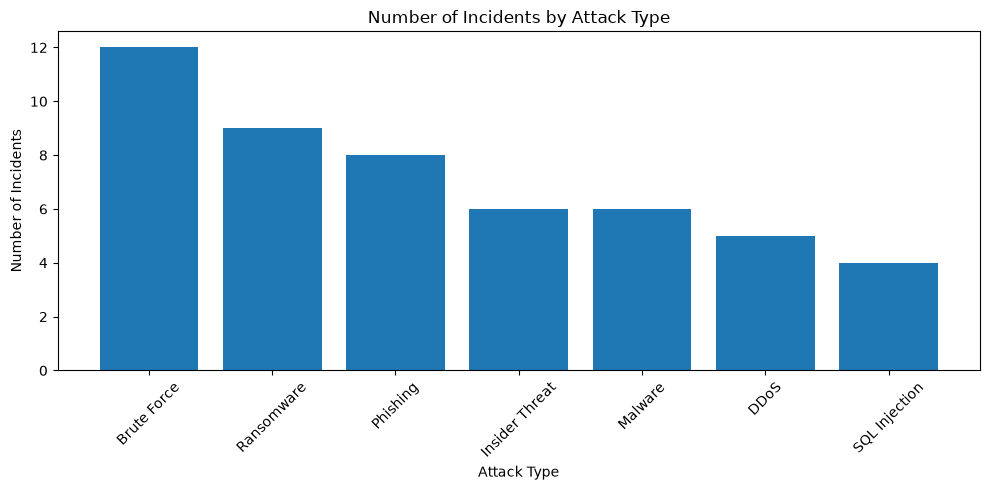

In [2]:
attack_counts = df["attack_type"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(attack_counts.index, attack_counts.values)

plt.title("Number of Incidents by Attack Type")
plt.xlabel("Attack Type")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2️⃣ Pie Chart  
→ Create a pie chart to visualize the distribution of severity levels.

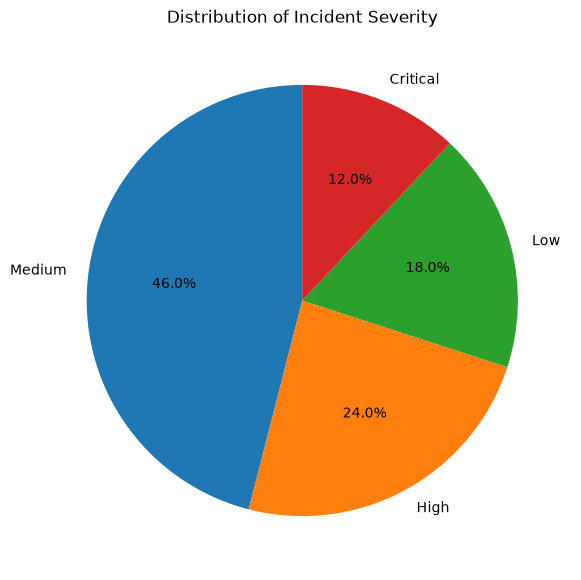

In [3]:
severity_counts = df["severity"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    severity_counts.values,
    labels=severity_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Incident Severity")
plt.show()

3️⃣ Histogram  
→ Plot a histogram of response_time_hours to visualize the response time distribution.

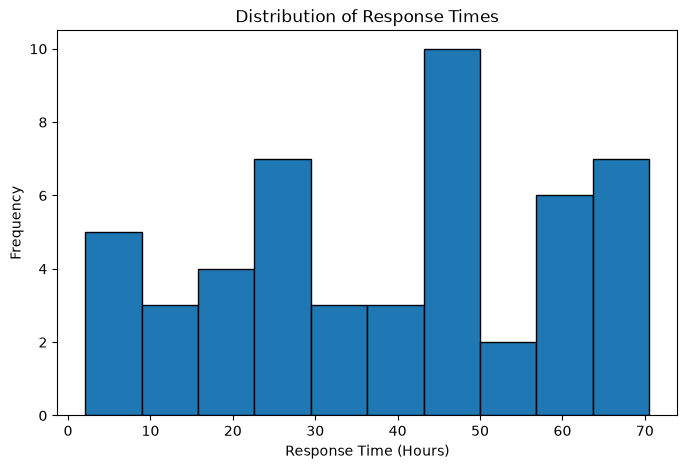

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(df["response_time_hours"], bins=10, edgecolor="black")

plt.title("Distribution of Response Times")
plt.xlabel("Response Time (Hours)")
plt.ylabel("Frequency")
plt.show()

4️⃣ Line Chart  
→ Plot a line chart showing total financial_impact_usd over time (monthly or daily).

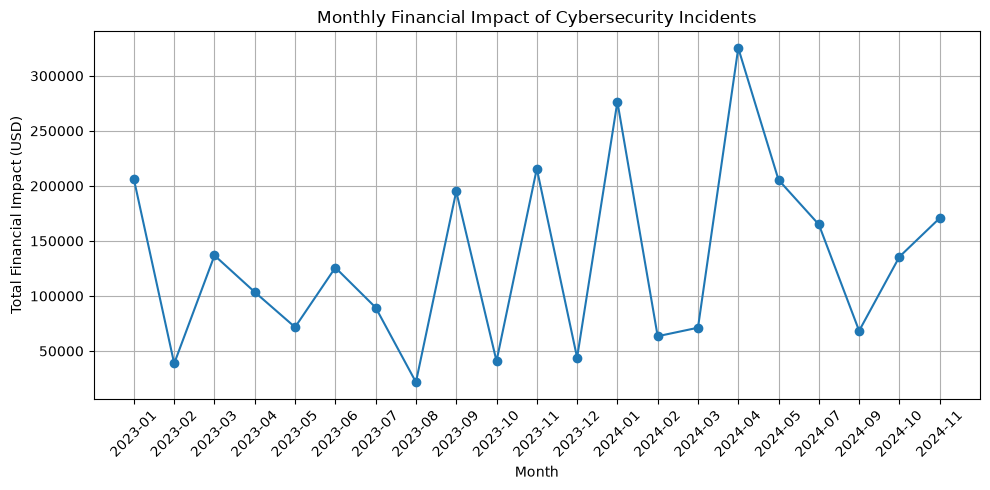

In [5]:
df["date"] = pd.to_datetime(df["date"])

monthly_impact = (
    df.groupby(df["date"].dt.to_period("M"))["financial_impact_usd"]
    .sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_impact.index.astype(str),
    monthly_impact.values,
    marker="o"
)

plt.title("Monthly Financial Impact of Cybersecurity Incidents")
plt.xlabel("Month")
plt.ylabel("Total Financial Impact (USD)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


5️⃣ Scatter Plot  
→ Create a scatter plot comparing data_loss_gb (x-axis) and financial_impact_usd (y-axis),  
   colored by severity.

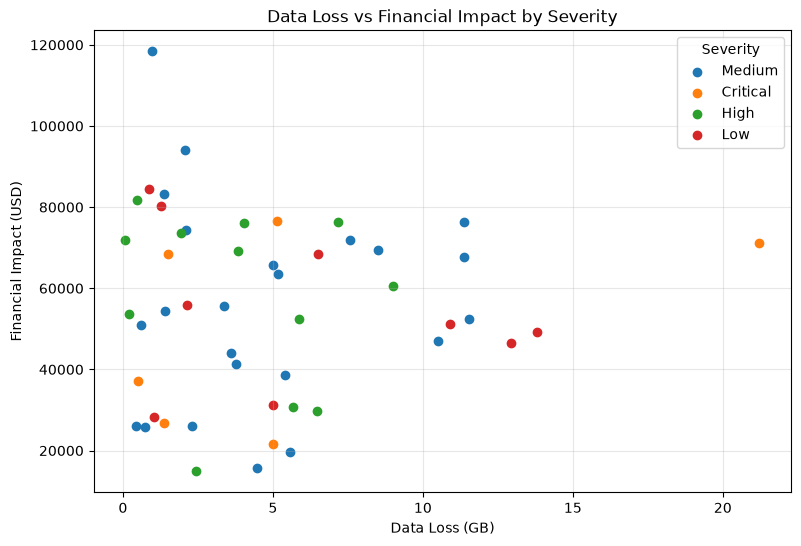

In [6]:
plt.figure(figsize=(9, 6))

for severity in df["severity"].unique():
    subset = df[df["severity"] == severity]

    plt.scatter(
        subset["data_loss_gb"],
        subset["financial_impact_usd"],
        label=severity
    )

plt.title("Data Loss vs Financial Impact by Severity")
plt.xlabel("Data Loss (GB)")
plt.ylabel("Financial Impact (USD)")
plt.legend(title="Severity")
plt.grid(True, alpha=0.3)
plt.show()